# AI Data Analyst Agent

**Dataset:** House Price India

## Objective

This project automatically analyzes a house price dataset, cleans missing values, performs exploratory data analysis (EDA), builds a machine learning model, and generates useful insights.

# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

 

In [2]:
df = pd.read_csv("../data/House Price India.csv")

In [3]:
df.head()   

,id,Date,number of bedrooms,number of bathrooms,living area,lot area,number of floors,waterfront present,number of views,condition of the house,...,Built Year,Renovation Year,Postal Code,Lattitude,Longitude,living_area_renov,lot_area_renov,Number of schools nearby,Distance from the airport,Price
0,6762810635,42491,4,2.50,2920,4000,1.5,0,0,5,...,1909,0,122004,52.8878,-114.470,2470,4000,2,51,1400000
1,6762810998,42491,5,2.75,2910,9480,1.5,0,0,3,...,1939,0,122004,52.8852,-114.468,2940,6600,1,53,1200000
2,6762812605,42491,4,2.50,3310,42998,2.0,0,0,3,...,2001,0,122005,52.9532,-114.321,3350,42847,3,76,838000
3,6762812919,42491,3,2.00,2710,4500,1.5,0,0,4,...,1929,0,122006,52.9047,-114.485,2060,4500,1,51,805000
4,6762813105,42491,3,2.50,2600,4750,1.0,0,0,4,...,1951,0,122007,52.9133,-114.590,2380,4750,1,67,790000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14619 entries, 0 to 14618
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     14619 non-null  int64  
 1   Date                                   14619 non-null  int64  
 2   number of bedrooms                     14619 non-null  int64  
 3   number of bathrooms                    14619 non-null  float64
 4   living area                            14619 non-null  int64  
 5   lot area                               14619 non-null  int64  
 6   number of floors                       14619 non-null  float64
 7   waterfront present                     14619 non-null  int64  
 8   number of views                        14619 non-null  int64  
 9   condition of the house                 14619 non-null  int64  
 10  grade of the house                     14619 non-null  int64  
 11  Ar

In [5]:
df.isnull().sum()

id                                       0
Date                                     0
number of bedrooms                       0
number of bathrooms                      0
living area                              0
lot area                                 0
number of floors                         0
waterfront present                       0
number of views                          0
condition of the house                   0
grade of the house                       0
Area of the house(excluding basement)    0
Area of the basement                     0
Built Year                               0
Renovation Year                          0
Postal Code                              0
Lattitude                                0
Longitude                                0
living_area_renov                        0
lot_area_renov                           0
Number of schools nearby                 0
Distance from the airport                0
Price                                    0
dtype: int6

In [6]:
# Missing percentage
missing_percentage = df.isnull().mean() * 100

print("Missing percentage:")
print(missing_percentage)

Missing percentage:
id                                       0.0
Date                                     0.0
number of bedrooms                       0.0
number of bathrooms                      0.0
living area                              0.0
lot area                                 0.0
number of floors                         0.0
waterfront present                       0.0
number of views                          0.0
condition of the house                   0.0
grade of the house                       0.0
Area of the house(excluding basement)    0.0
Area of the basement                     0.0
Built Year                               0.0
Renovation Year                          0.0
Postal Code                              0.0
Lattitude                                0.0
Longitude                                0.0
living_area_renov                        0.0
lot_area_renov                           0.0
Number of schools nearby                 0.0
Distance from the airport          

In [7]:
# Handle missing values

for col in df.columns:

    if df[col].isnull().sum() > 0:

        # Object / categorical column
        if df[col].dtype == "object":
            df[col].fillna(df[col].mode()[0], inplace=True)

        # Numerical column
        else:
            # Skewed data → Median
            if abs(df[col].skew()) >= 1:
                df[col].fillna(df[col].median(), inplace=True)

            # Approximately normal → Mean
            else:
                df[col].fillna(df[col].mean(), inplace=True)

In [8]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
id                                       0
Date                                     0
number of bedrooms                       0
number of bathrooms                      0
living area                              0
lot area                                 0
number of floors                         0
waterfront present                       0
number of views                          0
condition of the house                   0
grade of the house                       0
Area of the house(excluding basement)    0
Area of the basement                     0
Built Year                               0
Renovation Year                          0
Postal Code                              0
Lattitude                                0
Longitude                                0
living_area_renov                        0
lot_area_renov                           0
Number of schools nearby                 0
Distance from the airport                0
Price                  

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns

Index(['id', 'Date', 'number of bedrooms', 'number of bathrooms',
       'living area', 'lot area', 'number of floors', 'waterfront present',
       'number of views', 'condition of the house', 'grade of the house',
       'Area of the house(excluding basement)', 'Area of the basement',
       'Built Year', 'Renovation Year', 'Postal Code', 'Lattitude',
       'Longitude', 'living_area_renov', 'lot_area_renov',
       'Number of schools nearby', 'Distance from the airport', 'Price'],
      dtype='object')

In [11]:
df.describe()

,id,Date,number of bedrooms,number of bathrooms,living area,lot area,number of floors,waterfront present,number of views,condition of the house,...,Built Year,Renovation Year,Postal Code,Lattitude,Longitude,living_area_renov,lot_area_renov,Number of schools nearby,Distance from the airport,Price
count,1.461900e+04,14619.000000,14619.000000,14619.000000,14619.000000,1.461900e+04,14619.000000,14619.000000,14619.000000,14619.000000,...,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,14619.000000,1.461900e+04
mean,6.762821e+09,42604.546412,3.379233,2.129557,2098.156851,1.509369e+04,1.502326,0.007661,0.232848,3.430399,...,1970.929817,90.930228,122033.064300,52.792843,-114.403996,1996.641836,12754.003078,2.012244,64.951433,5.388063e+05
std,6.237162e+03,67.343747,0.938655,0.769955,928.218740,3.792089e+04,0.540241,0.087196,0.765651,0.664047,...,29.491743,416.230218,19.081451,0.137525,0.141325,691.078387,26059.234785,0.817312,8.936129,3.672294e+05
min,6.762810e+09,42491.000000,1.000000,0.500000,370.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,1900.000000,0.000000,122003.000000,52.385900,-114.709000,460.000000,651.000000,1.000000,50.000000,7.800000e+04
25%,6.762815e+09,42546.000000,3.000000,1.750000,1440.000000,5.010500e+03,1.000000,0.000000,0.000000,3.000000,...,1951.000000,0.000000,122017.000000,52.707600,-114.519000,1490.000000,5097.500000,1.000000,57.000000,3.200000e+05
50%,6.762821e+09,42600.000000,3.000000,2.250000,1930.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,...,1975.000000,0.000000,122032.000000,52.806400,-114.421000,1850.000000,7620.000000,2.000000,65.000000,4.500000e+05
75%,6.762826e+09,42662.000000,4.000000,2.500000,2570.000000,1.080000e+04,2.000000,0.000000,0.000000,4.000000,...,1997.000000,0.000000,122048.000000,52.908900,-114.315000,2380.000000,10125.000000,3.000000,73.000000,6.450000e+05
max,6.762832e+09,42734.000000,33.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,...,2015.000000,2015.000000,122072.000000,53.007600,-113.505000,6110.000000,560617.000000,3.000000,80.000000,7.700000e+06


In [12]:
df.dtypes

id                                         int64
Date                                       int64
number of bedrooms                         int64
number of bathrooms                      float64
living area                                int64
lot area                                   int64
number of floors                         float64
waterfront present                         int64
number of views                            int64
condition of the house                     int64
grade of the house                         int64
Area of the house(excluding basement)      int64
Area of the basement                       int64
Built Year                                 int64
Renovation Year                            int64
Postal Code                                int64
Lattitude                                float64
Longitude                                float64
living_area_renov                          int64
lot_area_renov                             int64
Number of schools ne

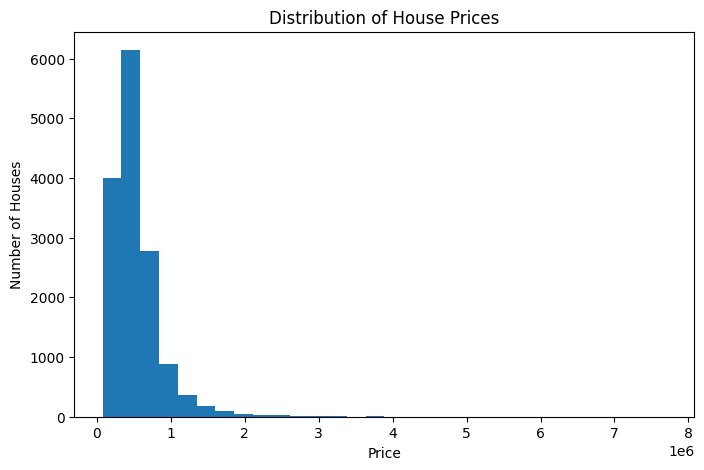

In [13]:
plt.figure(figsize=(8,5))
plt.hist(df["Price"], bins=30)

plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Number of Houses")

plt.show()

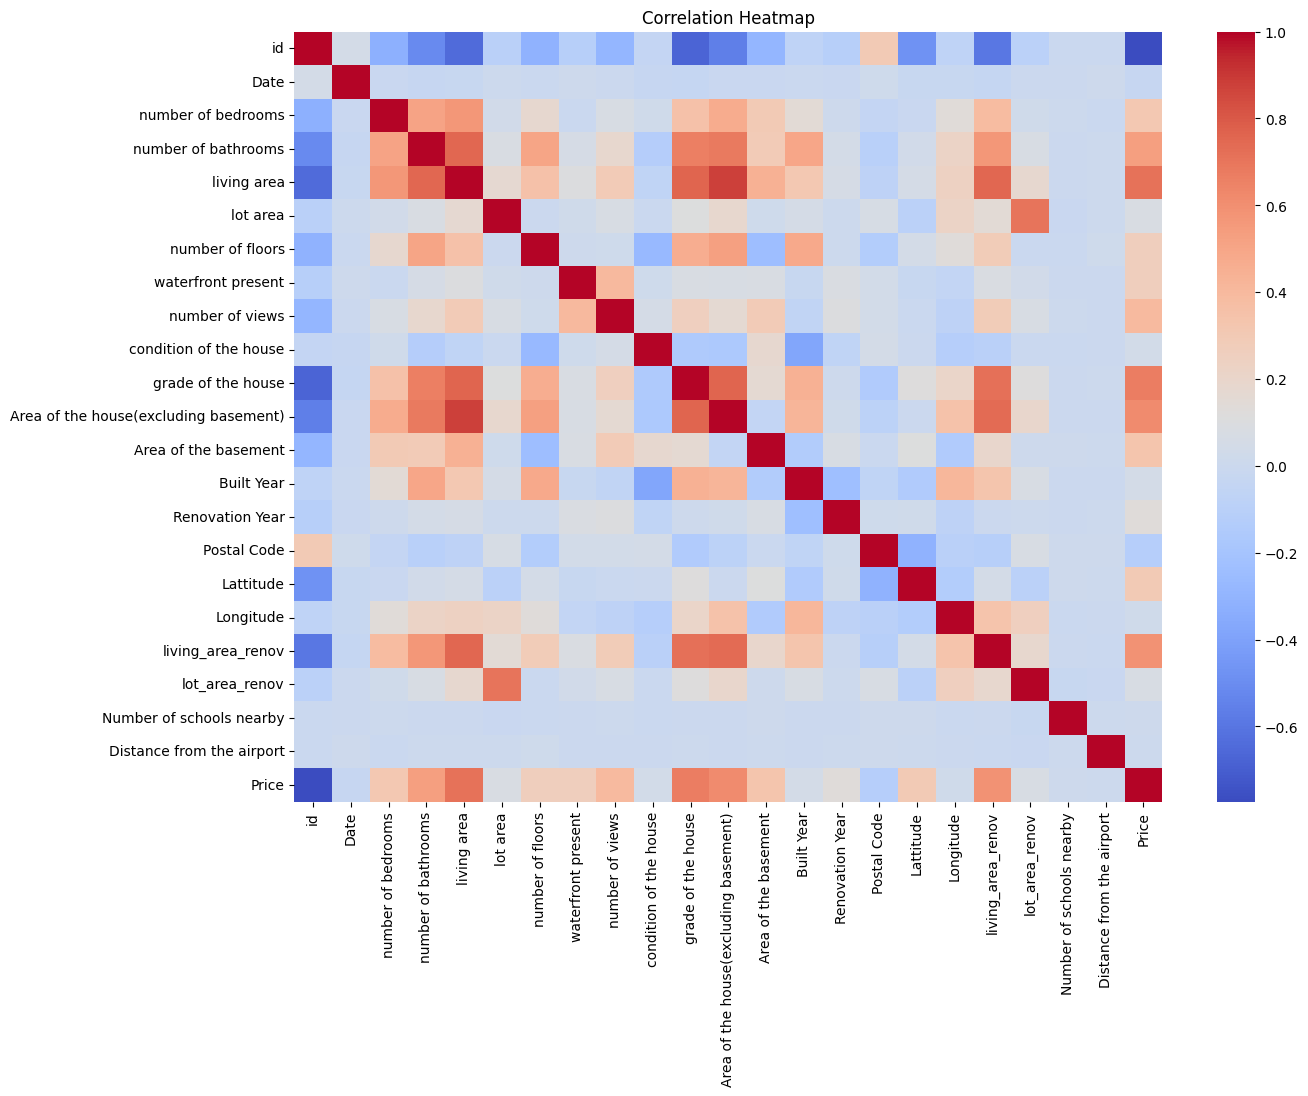

In [14]:
plt.figure(figsize=(14,10))

sns.heatmap(df.corr(numeric_only=True),
            annot=False,
            cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [15]:
price_corr = df.corr(numeric_only=True)["Price"].sort_values(ascending=False)

price_corr

Price                                    1.000000
living area                              0.712276
grade of the house                       0.671805
Area of the house(excluding basement)    0.615179
living_area_renov                        0.585021
number of bathrooms                      0.532031
number of views                          0.394954
Area of the basement                     0.330499
number of bedrooms                       0.308165
Lattitude                                0.297570
waterfront present                       0.263943
number of floors                         0.262649
Renovation Year                          0.133362
lot area                                 0.082117
lot_area_renov                           0.075697
Built Year                               0.050936
condition of the house                   0.040609
Longitude                                0.024807
Number of schools nearby                 0.009904
Distance from the airport                0.004074


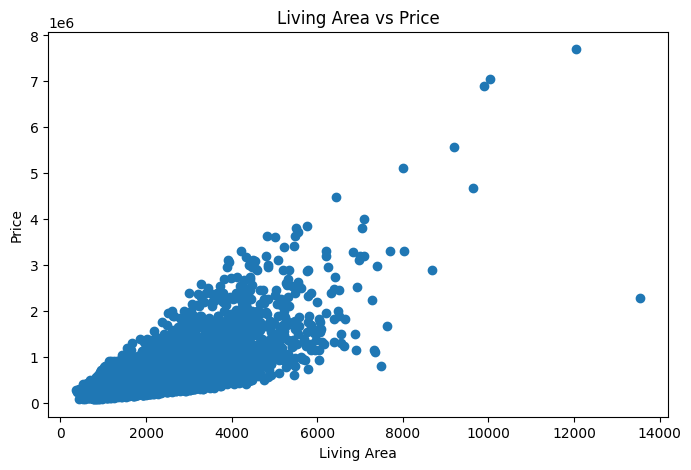

In [16]:
plt.figure(figsize=(8,5))

plt.scatter(df["living area"], df["Price"])

plt.title("Living Area vs Price")
plt.xlabel("Living Area")
plt.ylabel("Price")

plt.show()

# Feature Engineering

In [17]:
df["Date"].head()

0    42491
1    42491
2    42491
3    42491
4    42491
Name: Date, dtype: int64

In [18]:
df["Date"] = pd.to_datetime(df["Date"], origin="1899-12-30", unit="D")

df["Date"]

0       2016-05-01
1       2016-05-01
2       2016-05-01
3       2016-05-01
4       2016-05-01
           ...    
14614   2016-12-30
14615   2016-12-30
14616   2016-12-30
14617   2016-12-30
14618   2016-12-30
Name: Date, Length: 14619, dtype: datetime64[ns]

In [19]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

In [20]:
df[["Date", "Year", "Month", "Day"]].head()

,Date,Year,Month,Day
0,2016-05-01,2016,5,1
1,2016-05-01,2016,5,1
2,2016-05-01,2016,5,1
3,2016-05-01,2016,5,1
4,2016-05-01,2016,5,1


In [21]:
df.drop("Date", axis=1, inplace=True)

In [22]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [23]:
print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (14619, 24)
Target (y): (14619,)


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [25]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (11695, 24)
X_test : (2924, 24)
y_train: (11695,)
y_test : (2924,)
